# Demo 07 — Unsupervised Learning + Hyperparameter Tuning

**Machine Learning with scikit-learn — Session 07**

รันตามสไลด์คาบ 7 — หาโครงสร้างที่ไม่มีใครติดป้ายให้ (clustering, PCA) แล้วเรียน tuning โมเดลอย่างมีวินัย

## Setup — wine dataset: 178 ไวน์ × 13 สารเคมี (ซ่อนสายพันธุ์องุ่น 3 สายพันธุ์ไว้)

**สำคัญ: วันนี้ไม่มี y** — KMeans เห็นแค่ X ส่วน y จะใช้ "ตรวจคำตอบ" ตอนท้ายเท่านั้น

In [1]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

X, y = load_wine(return_X_y=True)
Xs = StandardScaler().fit_transform(X)   # clustering ก็เป็นเรื่อง "ระยะทาง" → scale ก่อนเสมอ!
print(X.shape)

(178, 13)


## Slide 4 — KMeans: plant flags, regroup, repeat

In [2]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = km.fit_predict(Xs)          # ไม่มี y ในคำสั่งนี้เลย
labels[:20]

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
      dtype=int32)

## Slide 5 — Choosing k: elbow & silhouette

In [3]:
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=42).fit(Xs)
    print(f"k={k}  inertia={km.inertia_:7.1f}  silhouette={silhouette_score(Xs, km.labels_):.3f}")

k=2  inertia= 1658.8  silhouette=0.259
k=3  inertia= 1277.9  silhouette=0.285
k=4  inertia= 1175.4  silhouette=0.260
k=5  inertia= 1109.5  silhouette=0.202
k=6  inertia= 1046.0  silhouette=0.237


k=7  inertia=  981.6  silhouette=0.204
k=8  inertia=  935.2  silhouette=0.157


- elbow: มองหา "หักศอก" ของ inertia (ชะลอตัวราว k=3)
- silhouette (วัด -1..1): **พีคที่ k=3 (0.285)** ✓ — สองเครื่องมือชี้ไปทางเดียวกัน

## Slide 6 — ★ The reveal: KMeans found the 3 cultivars — blind

In [4]:
km3 = KMeans(3, n_init=10, random_state=42).fit(Xs)
print("cluster sizes:", np.bincount(km3.labels_))
print("adjusted Rand index vs hidden labels:", round(adjusted_rand_score(y, km3.labels_), 3))

cluster sizes: [65 51 62]
adjusted Rand index vs hidden labels: 0.897


**0.897** — อัลกอริทึมไม่เคยเห็น label เลย แต่ค้นพบสายพันธุ์องุ่น 3 กลุ่มที่นักกีตาร์...ตี๋...ขอโทษ นักพันธุ์ศาสตร์ใช้เวลาหลายสิบปีจัดให้ 🍷

## Slide 7 — Clusters are only useful if you can NAME them

In [5]:
import pandas as pd
df = pd.DataFrame(X, columns=load_wine().feature_names)
df["cluster"] = km3.labels_
df.groupby("cluster")[["alcohol", "flavanoids", "proline"]].mean().round(1)

,alcohol,flavanoids,proline
cluster,,,
0,12.3,2.0,510.2
1,13.1,0.8,619.1
2,13.7,3.0,1100.2


ลองตั้งชื่อกลุ่มจากตารางนี้ — เช่น cluster ที่แอลกอฮอล์สูง/proline สูง = "กลุ่มไวน์เข้ม"
ในเชิงธุรกิจ นี่คือขั้น "ตั้งชื่อ segment" ที่ทำให้ผล clustering มีค่า

## Slide 9-10 — PCA: 13 features → 2 axes that matter most

In [6]:
pca2 = PCA(n_components=2)
Z = pca2.fit_transform(Xs)
print("explained variance:", pca2.explained_variance_ratio_.round(3), "=", pca2.explained_variance_ratio_.sum().round(3))

explained variance: [0.362 0.192] = 0.554


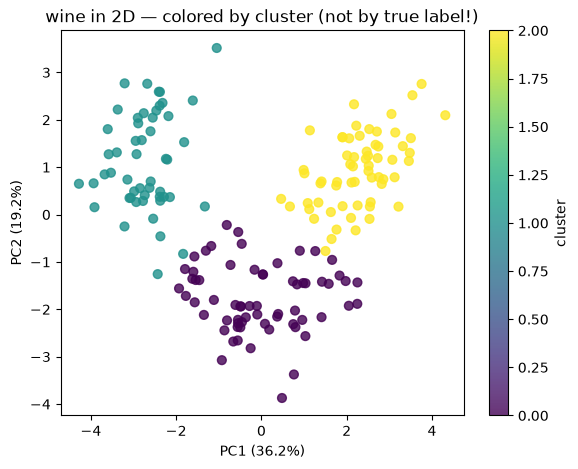

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6.5, 5))
plt.scatter(Z[:, 0], Z[:, 1], c=km3.labels_, cmap="viridis", s=40, alpha=0.8)
plt.xlabel("PC1 (36.2%)"); plt.ylabel("PC2 (19.2%)")
plt.title("wine in 2D — colored by cluster (not by true label!)")
plt.colorbar(label="cluster")
plt.show()

3 กลุ่มแยกกันชัดในภาพ 2 มิติ — ทั้งที่โมเดลทำงานใน 13 มิติ (และไม่เคยเห็น label)

## Part 2 — Tuning: Grid & Randomized search

### Slide 12-13 — หลักการ

GridSearchCV = ลองทุกชุดค่าในกริด × 5 folds · RandomizedSearchCV = สุ่ม n_iter จุดจาก distribution (ถูกกว่ามากเมื่อกริดใหญ่)
ทุกอย่างวัดด้วย **CV บน train เท่านั้น** — test ยังนอนเก็บตัวอยู่

In [8]:
from scipy.stats import randint
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.datasets import load_breast_cancer

Xc, yc = load_breast_cancer(return_X_y=True)
Xctr, Xcte, yctr, ycte = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=42)

rf_default = RandomForestClassifier(random_state=42).fit(Xctr, yctr)
print("RF default test:", round(rf_default.score(Xcte, ycte), 3))

RF default test: 0.958


In [9]:
param_dist = {
    "n_estimators": randint(50, 500),
    "max_depth": [None, 4, 6, 8, 12],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
}
rs = RandomizedSearchCV(RandomForestClassifier(random_state=42), param_dist,
                        n_iter=30, cv=5, random_state=42, n_jobs=-1)
rs.fit(Xctr, yctr)
print("best CV:", round(rs.best_score_, 3), "| params:", rs.best_params_)
print("tuned test:", round(rs.score(Xcte, ycte), 3))

best CV: 0.965 | params: {'max_depth': 8, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 97}
tuned test: 0.958


ผลแบบตรงไปตรงมา: CV ดีขึ้น 0.958 → 0.965 แต่ **test อยู่ที่ 0.958 เท่าเดิม** — ข้อมูลนี้ใกล้เพดานแล้ว
กระบวนการถูกต้องอยู่ดี และเรารายงานทั้งสองตัวเลขตามตรง (เรื่องนี้จะเจออีกครั้งตอนทำโปรเจ็ค)

## Slide 15 — Learning curves: more data or more model?

In [10]:
import numpy as np
from sklearn.model_selection import learning_curve

sizes, tr_scores, va_scores = learning_curve(
    RandomForestClassifier(random_state=42, n_jobs=-1), Xc, yc, cv=5,
    train_sizes=np.array([0.1, 0.25, 0.5, 0.75, 1.0]))
print("sizes     :", sizes)
print("train     :", tr_scores.mean(1).round(3), "← ท่องจำที่ขนาดไหนก็ 1.0")
print("validation:", va_scores.mean(1).round(3), "← ยิ่งมี data ยิ่งดีขึ้น")

sizes     : [ 45 113 227 341 455]
train     : [1. 1. 1. 1. 1.] ← ท่องจำที่ขนาดไหนก็ 1.0
validation: [0.726 0.921 0.954 0.961 0.956] ← ยิ่งมี data ยิ่งดีขึ้น


## Slide 17 — Save the winner (the WHOLE pipeline) with joblib

In [11]:
import joblib
joblib.dump(rs.best_estimator_, "best_rf.joblib")

loaded = joblib.load("best_rf.joblib")
loaded.predict(Xcte[:3])

array([1, 0, 1])

---
✅ **จบ Demo 07** — **Lab 07**: `excercises/07.clustering_tuning_exercise.ipynb`